In [7]:
from multiclass_functions import *
import torch
from torch import nn, optim
from torchvision import datasets, transforms
from torch.utils.data import TensorDataset, DataLoader
import numpy as np
import matplotlib.pyplot as plt
import os
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(DEVICE)

cpu


In [20]:
BATCH_SIZE = 32
LR = 1e-3
EPOCH = 30
criterion = nn.CrossEntropyLoss()
new_model_train = True

model_type = 'MLP'
dataset = 'CIFAR10'

os.makedirs('results', exist_ok=True)

save_model_path = f'results/{model_type}_{dataset}.pt'

In [ ]:
transform_train = transforms.Compose([
    transforms.AutoAugment(transforms.AutoAugmentPolicy.CIFAR10),
    transforms.ToTensor()

])
transform_test = transforms.ToTensor()

train_DS = datasets.CIFAR10(root = 'data', train=True, download=False, transform=transform_train)
test_DS = datasets.CIFAR10(root = 'data', train=False, download=False, transform=transform_test)
train_DL = DataLoader(train_DS, batch_size = BATCH_SIZE, shuffle=True)
test_DL = DataLoader(test_DS, batch_size = BATCH_SIZE, shuffle=False)

In [27]:
print(train_DS.data.shape)

(50000, 32, 32, 3)


In [28]:
print(train_DS)
print(test_DS)
print(test_DS.classes)
print(test_DS.class_to_idx)

Dataset CIFAR10
    Number of datapoints: 50000
    Root location: data
    Split: Train
    StandardTransform
Transform: ToTensor()
Dataset CIFAR10
    Number of datapoints: 10000
    Root location: data
    Split: Test
    StandardTransform
Transform: ToTensor()
['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
{'airplane': 0, 'automobile': 1, 'bird': 2, 'cat': 3, 'deer': 4, 'dog': 5, 'frog': 6, 'horse': 7, 'ship': 8, 'truck': 9}


torch.Size([32, 3, 32, 32])
truck


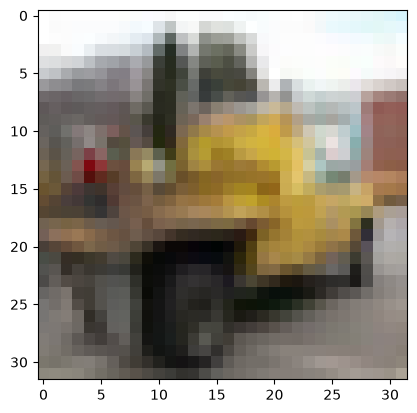

In [29]:
x_batch, y_batch = next(iter(train_DL))
print(x_batch.shape)

plt.imshow(x_batch[0].permute(1,2,0))
print(test_DS.classes[y_batch[0]])

In [30]:
print(type(train_DS.data))
print(train_DS.data.shape)
print(train_DS.data.dtype)
print(train_DS.data[0][0][0][0])  # 픽셀하나를 임의로 본것
print('-'*30)

print(type(x_batch.data))
print(x_batch.shape)
print(x_batch.dtype)

<class 'numpy.ndarray'>
(50000, 32, 32, 3)
uint8
59
------------------------------
<class 'torch.Tensor'>
torch.Size([32, 3, 32, 32])
torch.float32


In [31]:
class MLP(nn.Module):
  def __init__(self):
    super().__init__()
    self.linear = nn.Sequential(nn.Linear(3*32*32, 30),
                                nn.BatchNorm1d(30),
                                nn.ReLU(),
                                nn.Linear(30, 10)
                                )
  def forward(self, x):
    x = torch.flatten(x, start_dim=1)
    x = self.linear(x)
    return x

class MLP_shallow(nn.Module): 
  def __init__(self):
    super().__init__()
    self.linear = nn.Sequential(nn.Linear(3*32*32, 512),
                                nn.BatchNorm1d(512),
                                nn.ReLU(),
                                nn.Linear(512, 256),
                                nn.BatchNorm1d(256),
                                nn.ReLU(),
                                nn.Linear(256, 10)
                                )
  def forward(self, x):
    x = torch.flatten(x, start_dim=1)
    x = self.linear(x)
    return x

class MLP_drop(nn.Module): 
  def __init__(self):
    super().__init__()
    self.linear = nn.Sequential(nn.Linear(3*32*32, 510),
                                nn.BatchNorm1d(512),
                                nn.ReLU(),
                                nn.Linear(512, 256),
                                nn.BatchNorm1d(256),
                                nn.ReLU(),
                                nn.Dropout(p=0.3),
                                nn.Linear(256, 10)
                                )
  def forward(self, x):
    x = torch.flatten(x, start_dim=1)
    x = self.linear(x)
    return x

In [32]:
model = globals()[model_type]().to(DEVICE)
print(model)

x_batch, _ = next(iter(train_DL))
print(x_batch.shape)

MLP(
  (linear): Sequential(
    (0): Linear(in_features=3072, out_features=30, bias=True)
    (1): BatchNorm1d(30, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Linear(in_features=30, out_features=10, bias=True)
  )
)
torch.Size([32, 3, 32, 32])


In [ ]:
if new_model_train:
  optimizer = optim.Adam(model.parameters(), lr=LR)
  loss_history = Train(model, train_DL, criterion, optimizer, EPOCH)

  torch.save(model, save_model_path)

  plt.figure()
  plt.plot(range(1, EPOCH+1), loss_history)
  plt.xlabel('Epoch')
  plt.ylabel('Loss')
  plt.title('Train Loss')
  plt.grid()

Epoch : 1, train loss : 1.760
------------------------------
Epoch : 2, train loss : 1.597
------------------------------
Epoch : 3, train loss : 1.538
------------------------------
Epoch : 4, train loss : 1.504
------------------------------
Epoch : 5, train loss : 1.477
------------------------------
Epoch : 6, train loss : 1.454
------------------------------
Epoch : 7, train loss : 1.437
------------------------------
Epoch : 8, train loss : 1.427
------------------------------
Epoch : 9, train loss : 1.415
------------------------------
Epoch : 10, train loss : 1.405
------------------------------


In [ ]:
load_model = torch.load(save_model_path, map_location=DEVICE, weights_only=False)

In [ ]:
Test(load_model, test_DL)
print(count_params(load_model))

Test accuracy : 5126 / 10000 (51.3 %)
289885


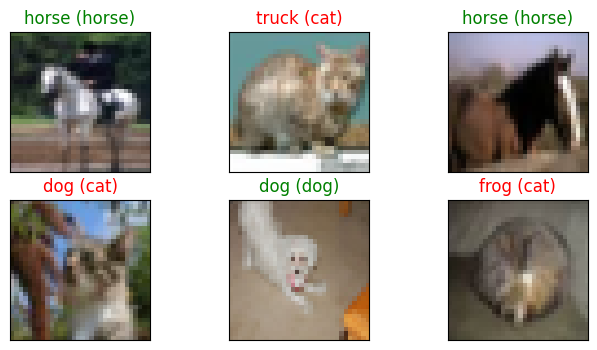

In [ ]:
Test_plot(load_model, test_DL)

(array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]),
 [Text(0, 0, 'airplane'),
  Text(1, 0, 'automobile'),
  Text(2, 0, 'bird'),
  Text(3, 0, 'cat'),
  Text(4, 0, 'deer'),
  Text(5, 0, 'dog'),
  Text(6, 0, 'frog'),
  Text(7, 0, 'horse'),
  Text(8, 0, 'ship'),
  Text(9, 0, 'truck')])

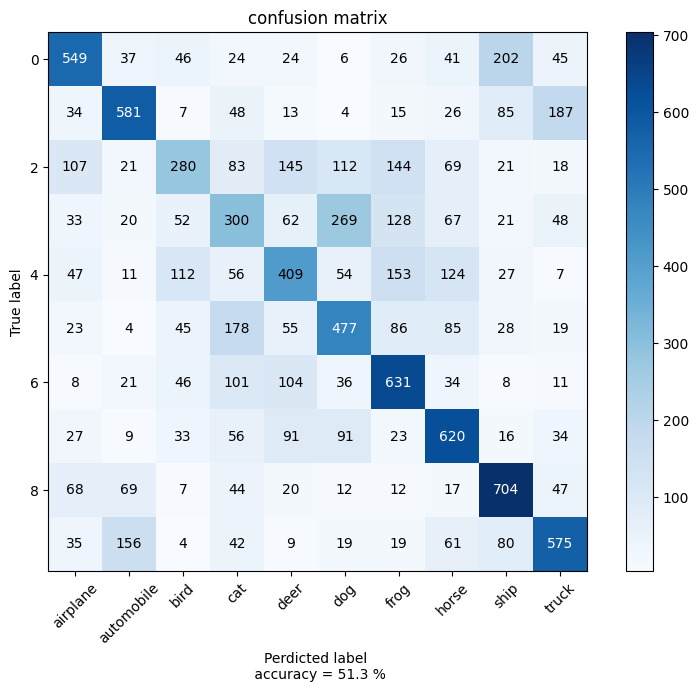

In [ ]:
confusion = get_conf(load_model, test_DL)
plot_confusion_matrix(confusion, test_DS.classes)
plt.xticks(rotation=45)